# Generative tagging with Qwen3 — Part B · Evaluation

Loads the Part B adapter in vLLM, evaluates it with constrained decoding, and compares all models.

**Public Weights & Biases project:** [https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags](https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags)

**Adapter repository:** `rajatsxngh/qwen3-instruct-tag-adapter` (originally created as `hw5b-qwen3-instruct-tag-adapter`, the name that appears in the code and outputs below; Hugging Face redirects the old name)

Run this notebook in a **fresh Colab GPU runtime** (A100, L4, or RTX PRO 6000).
Use separate sessions for training and vLLM inference. Add `HF_TOKEN` (with
permission to write the two adapter repositories) and `WANDB_API_KEY` to
Colab Secrets and enable notebook access. Credentials are read without printing
them. The dataset is `multiclass_split.csv` (see `data/README.md`).

## Install the inference environment

Start with a fresh GPU runtime. Run training in its own notebook first;
this notebook loads the best saved adapter and never trains or tunes on test data.
Part B inference additionally requires Part A's saved evaluation results.

In [1]:
import subprocess, sys
# The inference environment follows lecture notebooks 4B and 7B.
# It must be separate from both TRL and Axolotl training environments.
packages = [
    "transformers==4.57.6", "datasets==5.0.0", "peft==0.19.1",
    "accelerate==1.14.0", "evaluate==0.4.6", "vllm==0.11.0",
    "wandb>=0.19.0", "scikit-learn", "matplotlib", "seaborn", "tabulate",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
print("Inference packages installed. If Colab requests a restart, restart now and continue at Configuration.")

Inference packages installed. If Colab requests a restart, restart now and continue at Configuration.


## Configuration

In [2]:
import os, json, hashlib, platform, time
from pathlib import Path
import numpy as np
import pandas as pd

PART = 'B'
PHASE = 'inference'
SEED = 42
HF_USERNAME = "rajatsxngh"
HF_REPO_ID = 'rajatsxngh/hw5b-qwen3-instruct-tag-adapter'
HF_PRIVATE = True  # W&B must be public; Hub adapters may remain private.
WANDB_ENTITY = "rajat-utd"
WANDB_PROJECT = "hw5_decoder_tags"
WANDB_PROJECT_URL = 'https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags'
BASE_MODEL = 'Qwen/Qwen3-1.7B'
os.environ["WANDB_ENTITY"] = WANDB_ENTITY
os.environ["WANDB_PROJECT"] = WANDB_PROJECT
os.environ["TOKENIZERS_PARALLELISM"] = "false"
np.random.seed(SEED)
print({"part": PART, "phase": PHASE, "base_model": BASE_MODEL,
       "adapter_repository": HF_REPO_ID, "wandb_project": WANDB_PROJECT_URL})

{'part': 'B', 'phase': 'inference', 'base_model': 'Qwen/Qwen3-1.7B', 'adapter_repository': 'rajatsxngh/hw5b-qwen3-instruct-tag-adapter', 'wandb_project': 'https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags'}


## Authenticate using Colab Secrets

In [3]:
from google.colab import userdata
from huggingface_hub import login, HfApi
import wandb

def read_secret(name):
    try:
        value = userdata.get(name)
    except Exception:
        raise RuntimeError(
            f"Add {name} in Colab's Secrets panel and enable notebook access."
        ) from None
    if not value:
        raise RuntimeError(f"Colab Secret {name} is empty.")
    return value

os.environ["HF_TOKEN"] = read_secret("HF_TOKEN")
os.environ["WANDB_API_KEY"] = read_secret("WANDB_API_KEY")
login(token=os.environ["HF_TOKEN"], add_to_git_credential=False)
hf_api = HfApi(token=os.environ["HF_TOKEN"])
identity = hf_api.whoami()
assert identity["name"] == HF_USERNAME, "Sign in to the intended Hugging Face account."
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("Authenticated with Hugging Face and Weights & Biases.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: rajat7 (rajat-utd) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Authenticated with Hugging Face and Weights & Biases.


## Load and validate the original data splits

In [5]:
from google.colab import drive, files
drive.mount("/content/drive")
WORK_DIR = Path("/content/drive/MyDrive/HW5_Decoder_Tags")
RESULTS_DIR = WORK_DIR / "results"
WORK_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = WORK_DIR / "multiclass_split.csv"
if not CSV_PATH.exists():
    print("Select the instructor's multiclass_split.csv. It will be saved to Drive for all four notebooks.")
    uploaded = files.upload()
    if "multiclass_split.csv" not in uploaded:
        raise FileNotFoundError("Upload the file named multiclass_split.csv.")
    CSV_PATH.write_bytes(uploaded["multiclass_split.csv"])
    del uploaded

DATASET_SHA256 = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
df = pd.read_csv(CSV_PATH)
required = {"id", "text", "tag", "label", "split", "decoder_train", "val_subset"}
assert required <= set(df.columns), f"Missing columns: {required - set(df.columns)}"
assert not df[["id", "text", "tag", "label", "split"]].isna().any().any()
assert df["id"].is_unique, "Question IDs must be unique."
assert df.groupby("label")["tag"].nunique().eq(1).all()
assert df.groupby("tag")["label"].nunique().eq(1).all()
class_names = df.drop_duplicates("label").sort_values("label")["tag"].tolist()
assert len(class_names) == 10
train_df = df.loc[df["decoder_train"].eq(1)].copy().reset_index(drop=True)
monitor_df = df.loc[df["val_subset"].eq(1)].copy().reset_index(drop=True)
val_df = df.loc[df["split"].eq("val")].copy().reset_index(drop=True)
test_df = df.loc[df["split"].eq("test")].copy().reset_index(drop=True)
assert (len(train_df), len(monitor_df), len(val_df), len(test_df)) == (5000, 1000, 6276, 6275)
assert train_df["split"].eq("train").all()
assert monitor_df["split"].eq("val").all()
assert set(train_df["id"]).isdisjoint(val_df["id"])
assert set(train_df["id"]).isdisjoint(test_df["id"])
assert set(val_df["id"]).isdisjoint(test_df["id"])
assert set(monitor_df["id"]) <= set(val_df["id"])

# These exact functions are embedded identically in all four notebooks.
# Raw text is preserved; do not strip, clean, or add a trailing space.
def make_user_prompt(text):
    return f"Classify the TEXT by selecting one label from the following list: {class_names}. ### TEXT: {text}"

def make_base_prompt(text):
    return make_user_prompt(text) + " ### LABEL:"

print("Dataset:", CSV_PATH)
print("SHA-256:", DATASET_SHA256)
print("Classes:", class_names)
display(pd.DataFrame({"split": ["decoder_train", "val_subset", "validation", "test"],
                      "questions": [len(train_df), len(monitor_df), len(val_df), len(test_df)]}))

Mounted at /content/drive
Dataset: /content/drive/MyDrive/HW5_Decoder_Tags/multiclass_split.csv
SHA-256: 96782bf3e899d577e2c7cbfb23c31ac4f45397b23487697f75e8677d78633c3b
Classes: ['c#', 'java', 'php', 'javascript', 'android', 'jquery', 'c++', 'python', 'iphone', 'asp.net']


,split,questions
0,decoder_train,5000
1,val_subset,1000
2,validation,6276
3,test,6275


## GPU and inference libraries

In [6]:
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
import importlib.metadata
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from transformers import AutoTokenizer
from huggingface_hub import hf_hub_download, snapshot_download
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from vllm import LLM, SamplingParams
from vllm.lora.request import LoRARequest
from vllm.sampling_params import StructuredOutputsParams

assert torch.cuda.is_available(), "Select a fresh Colab GPU runtime before continuing."
assert torch.cuda.is_bf16_supported(), "Use an A100, L4, or RTX PRO 6000 runtime with BF16 support."
GPU_NAME = torch.cuda.get_device_name(0)
print("GPU:", GPU_NAME)
print({p: importlib.metadata.version(p) for p in ["torch", "transformers", "vllm", "peft", "wandb"]})

INFO 11-04 11:59:06 [__init__.py:216] Automatically detected platform cuda.
GPU: NVIDIA L4
{'torch': '2.8.0', 'transformers': '4.57.6', 'vllm': '0.11.0', 'peft': '0.19.1', 'wandb': '0.28.1'}


## Download and verify the exact best adapter

In [9]:
# Resolve a single immutable Hub commit before downloading any adapter files.
summary_name = f"training_summary_{PART}.json"
local_summary_path = RESULTS_DIR / summary_name
if local_summary_path.exists():
    training_summary = json.loads(local_summary_path.read_text())
    ADAPTER_REVISION = training_summary["adapter_revision"]
else:
    ADAPTER_REVISION = hf_api.model_info(HF_REPO_ID).sha
    summary_file = hf_hub_download(HF_REPO_ID, summary_name, revision=ADAPTER_REVISION)
    training_summary = json.loads(Path(summary_file).read_text())
    training_summary["adapter_revision"] = ADAPTER_REVISION

assert training_summary["part"] == PART
assert training_summary["base_model"] == BASE_MODEL
assert training_summary["adapter_repo_id"] == HF_REPO_ID
assert training_summary["dataset_sha256"] == DATASET_SHA256, "Training and inference must use the same CSV."
assert training_summary["class_names"] == class_names, "Tag ordering must match training."
assert training_summary["training_questions"] == 5000
assert training_summary["prompt_format"] == "hw5_single_tag_v1"
assert isinstance(ADAPTER_REVISION, str) and len(ADAPTER_REVISION) == 40

ADAPTER_DIR = Path(snapshot_download(HF_REPO_ID, revision=ADAPTER_REVISION))
hub_summary = json.loads((ADAPTER_DIR / summary_name).read_text())
for key in ["part", "base_model", "adapter_repo_id", "dataset_sha256", "class_names",
            "training_questions", "trainable_parameters", "training_time_seconds",
            "peak_gpu_memory_gb", "best_eval_loss", "prompt_format"]:
    assert hub_summary[key] == training_summary[key], f"Training metadata mismatch: {key}"
adapter_config = json.loads((ADAPTER_DIR / "adapter_config.json").read_text())
assert adapter_config["r"] == 128
assert adapter_config["peft_type"] == "LORA"
assert any((ADAPTER_DIR / name).exists() for name in ["adapter_model.safetensors", "adapter_model.bin"])

BASE_REVISION = training_summary.get("base_model_revision", training_summary.get("model_revision"))
assert isinstance(BASE_REVISION, str) and len(BASE_REVISION) == 40, "Training must record the base-model commit."
# Transformers 5 saves a list as extra_special_tokens; Transformers 4 calls
# that same list additional_special_tokens. Preserve the original Hub snapshot
# and translate only this configuration field in a separate tokenizer copy.
import shutil
import tempfile
from tokenizers import Tokenizer

tokenizer_config = json.loads((ADAPTER_DIR / "tokenizer_config.json").read_text())
TOKENIZER_DIR = ADAPTER_DIR
extra_tokens = tokenizer_config.get("extra_special_tokens")
if isinstance(extra_tokens, list):
    assert "additional_special_tokens" not in tokenizer_config or tokenizer_config["additional_special_tokens"] == extra_tokens, "Conflicting special-token lists."
    TOKENIZER_DIR = Path(tempfile.mkdtemp(prefix=f"hw5{PART.lower()}_tokenizer_{ADAPTER_REVISION[:8]}_"))
    for name in ["tokenizer.json", "tokenizer_config.json", "chat_template.jinja",
                 "special_tokens_map.json", "added_tokens.json", "vocab.json", "merges.txt"]:
        if (ADAPTER_DIR / name).exists():
            shutil.copy2(ADAPTER_DIR / name, TOKENIZER_DIR / name)
    tokenizer_config["additional_special_tokens"] = tokenizer_config.pop("extra_special_tokens")
    (TOKENIZER_DIR / "tokenizer_config.json").write_text(json.dumps(tokenizer_config, indent=2))
    for name in ["tokenizer.json", "chat_template.jinja"]:
        if (ADAPTER_DIR / name).exists():
            assert (TOKENIZER_DIR / name).read_bytes() == (ADAPTER_DIR / name).read_bytes()
    print("Translated the saved tokenizer configuration for Transformers 4; token IDs and chat template are unchanged.")

tokenizer = AutoTokenizer.from_pretrained(str(TOKENIZER_DIR), use_fast=True, local_files_only=True)
raw_tokenizer = Tokenizer.from_file(str(ADAPTER_DIR / "tokenizer.json"))
assert tokenizer.get_vocab() == raw_tokenizer.get_vocab(), "Tokenizer vocabulary or IDs changed."
for item in json.loads((ADAPTER_DIR / "tokenizer.json").read_text())["added_tokens"]:
    assert tokenizer.convert_tokens_to_ids(item["content"]) == item["id"]
    if item["special"]:
        assert item["id"] in tokenizer.all_special_ids
for name in ["bos_token", "eos_token", "pad_token", "unk_token"]:
    expected_token = tokenizer_config.get(name)
    if isinstance(expected_token, dict):
        expected_token = expected_token["content"]
    if name in tokenizer_config:
        assert getattr(tokenizer, name) == expected_token
masking_path = ADAPTER_DIR / f"masking_{PART}.json"
masking_evidence = json.loads(masking_path.read_text())
assert tokenizer.convert_ids_to_tokens(masking_evidence["supervised_token_ids"]) == masking_evidence["supervised_tokens"]
assert tokenizer.encode(masking_evidence["supervised_text"], add_special_tokens=False) == masking_evidence["supervised_token_ids"]
if "tokens" in masking_evidence:
    assert tokenizer.convert_ids_to_tokens(masking_evidence["input_ids"]) == masking_evidence["tokens"]
if PART == "B":
    assert tokenizer.apply_chat_template(
        [{"role": "user", "content": training_summary["prompt_example_user"]}],
        tokenize=False, add_generation_prompt=True, enable_thinking=False,
    ) == training_summary["prompt_example"], "Chat formatting differs from training."
print("Tokenizer verified against the saved vocabulary, special tokens, and training masking evidence.")
print("Adapter:", HF_REPO_ID)
print("Adapter commit:", ADAPTER_REVISION)
print("Base-model commit:", BASE_REVISION)
display(pd.DataFrame([{
    "training_questions": training_summary["training_questions"],
    "trainable_parameters": training_summary["trainable_parameters"],
    "training_minutes": training_summary["training_time_seconds"] / 60,
    "peak_gpu_memory_GB": training_summary["peak_gpu_memory_gb"],
    "training_GPU": training_summary["gpu_name"],
    "best_validation_loss": training_summary["best_eval_loss"],
}]))

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Translated the saved tokenizer configuration for Transformers 4; token IDs and chat template are unchanged.
Tokenizer verified against the saved vocabulary, special tokens, and training masking evidence.
Adapter: rajatsxngh/hw5b-qwen3-instruct-tag-adapter
Adapter commit: 12b978a9c5ee6344acc5ed1b302c048aced55772
Base-model commit: 70d244cc86ccca08cf5af4e1e306ecf908b1ad5e


,training_questions,trainable_parameters,training_minutes,peak_gpu_memory_GB,training_GPU,best_validation_loss
0,5000,139460608,39.517461,2.316281,NVIDIA L4,0.065417


## Reproduce the training prompt exactly

In [10]:
def make_inference_prompt(text):
    return tokenizer.apply_chat_template(
        [{"role": "user", "content": make_user_prompt(text)}],
        tokenize=False, add_generation_prompt=True, enable_thinking=False,
    )

assert make_user_prompt(training_summary["prompt_example_text"]) == training_summary["prompt_example_user"]
assert make_inference_prompt(training_summary["prompt_example_text"]) == training_summary["prompt_example"]
assert make_inference_prompt(training_summary["prompt_example_text"]).endswith("<think>\n\n</think>\n\n")
choices = class_names.copy()
tokenization_example = None

## Start vLLM and W&B logging

In [11]:
FREE_MAX_TOKENS = 64
CONSTRAINED_MAX_TOKENS = max(16, max(len(tokenizer.encode(c, add_special_tokens=False)) for c in choices) + 4)
MAX_MODEL_LEN = 1024

def encode_frame(frame):
    prompts = [make_inference_prompt(t) for t in frame["text"]]
    ids = tokenizer(prompts, add_special_tokens=False, truncation=False)["input_ids"]
    assert max(map(len, ids)) + FREE_MAX_TOKENS <= MAX_MODEL_LEN, "Do not silently truncate a prompt."
    # Explicit token IDs prevent the inference engine from inserting extra special tokens.
    return [{"prompt_token_ids": tokens} for tokens in ids], max(map(len, ids))

val_inputs, val_max_length = encode_frame(val_df)
test_inputs, test_max_length = encode_frame(test_df)
monitor_inputs, monitor_max_length = encode_frame(monitor_df)
print("Longest prompt lengths:", {"validation": val_max_length, "test": test_max_length,
                                 "monitoring": monitor_max_length})
print("Example prompt (repr preserves all whitespace):")
print(repr(make_inference_prompt(val_df.iloc[0]["text"])))
print("Allowed completions:", choices)

llm = LLM(
    model=BASE_MODEL,
    revision=BASE_REVISION,
    tokenizer=str(TOKENIZER_DIR),
    dtype="bfloat16",
    enable_lora=True,
    max_lora_rank=128,
    max_loras=1,
    max_model_len=MAX_MODEL_LEN,
    max_num_seqs=64,
    gpu_memory_utilization=0.65,
    enable_chunked_prefill=False,
    seed=SEED,
)
lora_request = LoRARequest(f"hw5{PART.lower()}_tag_adapter", 1, str(ADAPTER_DIR))
constrained_params = SamplingParams(
    temperature=0, seed=SEED, max_tokens=CONSTRAINED_MAX_TOKENS,
    structured_outputs=StructuredOutputsParams(choice=choices),
)
free_params = SamplingParams(temperature=0, seed=SEED, max_tokens=FREE_MAX_TOKENS)

run = wandb.init(
    entity=WANDB_ENTITY, project=WANDB_PROJECT,
    name=f"hw5{PART.lower()}_inference", job_type="evaluation",
    config={"part": PART, "base_model": BASE_MODEL, "base_revision": BASE_REVISION,
            "adapter_repository": HF_REPO_ID, "adapter_revision": ADAPTER_REVISION,
            "dataset_sha256": DATASET_SHA256, "seed": SEED,
            "validation_questions": len(val_df), "test_questions": len(test_df),
            "free_answer_questions": len(monitor_df), "temperature": 0,
            "constrained_max_tokens": CONSTRAINED_MAX_TOKENS, "free_max_tokens": FREE_MAX_TOKENS,
            "class_names": class_names, "gpu": GPU_NAME},
)
print("W&B evaluation run:", run.url)

Longest prompt lengths: {'validation': 599, 'test': 906, 'monitoring': 499}
Example prompt (repr preserves all whitespace):
'<|im_start|>user\nClassify the TEXT by selecting one label from the following list: [\'c#\', \'java\', \'php\', \'javascript\', \'android\', \'jquery\', \'c++\', \'python\', \'iphone\', \'asp.net\']. ### TEXT: Conflicting event-handling in jQuery <p>I have a <code>&lt;div&gt;</code> like this:</p>\n\n<pre><code>&lt;div id="Field1"&gt;\n  &lt;label id="label1"&gt;Name&lt;/label&gt;&lt;br/&gt;\n  &lt;input type="text" data-attr="text" style="..." id="input1"/&gt;&lt;br/&gt;\n  &lt;label id="instr1"/&gt;\n  &lt;div class="xfb-row-options1"&gt;\n    &lt;a class="button-delete" src="..." style="..."&gt;-&lt;/a&gt; \n  &lt;/div&gt;\n&lt;/div&gt;\n</code></pre>\n\n<p>I already have a jQuery function:</p>\n\n<pre><code>$("#fb_contentarea_col1down21 div").live("click", function(){\n  // some stuff to change the properties of the Field,\n  // like changing the field name, 

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

INFO 11-04 12:23:34 [model.py:547] Resolved architecture: Qwen3ForCausalLM


`torch_dtype` is deprecated! Use `dtype` instead!


INFO 11-04 12:23:34 [model.py:1510] Using max model len 1024
INFO 11-04 12:23:34 [scheduler.py:205] Chunked prefill is enabled with max_num_batched_tokens=8192.
WARNING 11-04 12:23:34 [lora.py:92] `lora_extra_vocab_size` is deprecated and will be removed in v0.12.0. Additional vocabulary support for LoRA adapters is being phased out.


generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

INFO 11-04 12:26:06 [llm.py:306] Supported_tasks: ['generate']


wandb: Detected [openai] in use.
wandb: Use W&B Weave for improved LLM call tracing. Install Weave with `pip install weave` then add `import weave` to the top of your script.
wandb: For more information, check out the docs at: https://weave-docs.wandb.ai


W&B evaluation run: https://wandb.ai/rajat-utd/hw5_decoder_tags/runs/lxt8b01s


## Evaluation helpers

In [12]:
def generate_rows(frame, inputs, params, adapter, label, constrained):
    start = time.perf_counter()
    outputs = llm.generate(inputs, sampling_params=params, lora_request=adapter, use_tqdm=True)
    elapsed = time.perf_counter() - start
    assert len(outputs) == len(frame)
    rows = []
    for source, request, output in zip(frame.itertuples(index=False), inputs, outputs):
        assert list(output.prompt_token_ids) == request["prompt_token_ids"], "Prompt order/tokenization changed."
        answer = output.outputs[0]
        raw = answer.text
        # Remove only surrounding whitespace; no case folding, tag extraction,
        # punctuation removal, JSON parsing, or removal of reasoning text.
        prediction = raw.strip()
        valid = prediction in class_names
        truncated = answer.finish_reason == "length"
        if constrained:
            assert raw in choices, f"Constrained output outside exact choices: {raw!r}"
            assert valid and not truncated, "Constrained generation did not finish with a complete allowed label."
        rows.append({"id": source.id, "true_tag": source.tag,
                     "raw_response": raw, "prediction": prediction,
                     "valid_tag": valid, "raw_exact_tag": raw in class_names,
                     "finish_reason": answer.finish_reason,
                     "generated_tokens": len(answer.token_ids), "truncated": truncated})
    predictions = pd.DataFrame(rows)
    dest = RESULTS_DIR / f"hw5{PART}_{label}.csv"
    predictions.to_csv(dest, index=False)
    print(f"{label}: {len(predictions):,} questions in {elapsed:.1f} seconds; saved {dest.name}")
    return predictions, elapsed

def score(predictions):
    assert predictions["valid_tag"].all()
    return {"accuracy": float(accuracy_score(predictions["true_tag"], predictions["prediction"])),
            "macro_f1": float(f1_score(predictions["true_tag"], predictions["prediction"],
                                        labels=class_names, average="macro", zero_division=0))}

def log_predictions(label, predictions):
    # The saved outputs and W&B table contain IDs, targets, and predictions, not question bodies.
    run.log({label: wandb.Table(dataframe=predictions)})

def plot_confusion(predictions, label):
    cm = confusion_matrix(predictions["true_tag"], predictions["prediction"], labels=class_names)
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set(xlabel="Predicted tag", ylabel="True tag", title=f"HW5{PART} {label} confusion matrix")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"hw5{PART}_{label}_confusion_matrix.png", dpi=160, bbox_inches="tight")
    run.log({f"{label}/confusion_matrix": wandb.Image(fig)})
    display(fig)
    plt.close(fig)
    return cm

def ranked_confusions(cm, limit=5):
    items = [{"true_tag": class_names[i], "predicted_tag": class_names[j], "count": int(cm[i,j])}
             for i in range(len(class_names)) for j in range(len(class_names)) if i != j and cm[i,j] > 0]
    return sorted(items, key=lambda r: (-r["count"], r["true_tag"], r["predicted_tag"]))[:limit]

## Fine-tuned model: full validation and test splits

Adding requests:   0%|          | 0/6276 [00:00<?, ?it/s]

WARNING 11-04 12:27:24 [processor.py:215] vLLM has deprecated support for supporting different tokenizers for different LoRAs. By default, vLLM uses base model's tokenizer. If you are using a LoRA with its own tokenizer, consider specifying `--tokenizer [lora_path]` to use the LoRA tokenizer.


Processed prompts:   0%|          | 0/6276 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

validation_constrained: 6,276 questions in 105.5 seconds; saved hw5B_validation_constrained.csv


Adding requests:   0%|          | 0/6275 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/6275 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

test_constrained: 6,275 questions in 104.4 seconds; saved hw5B_test_constrained.csv


,split,questions,accuracy,macro_f1
0,validation,6276,0.955226,0.949372
1,test,6275,0.952510,0.947952


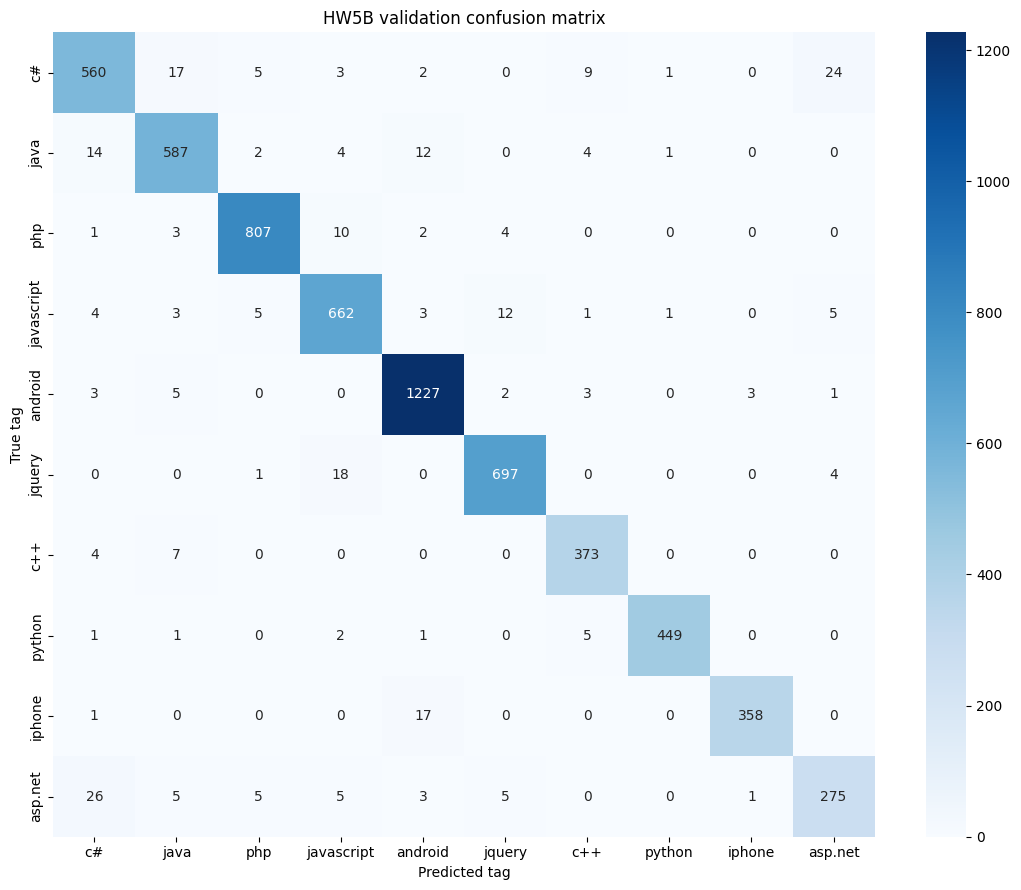

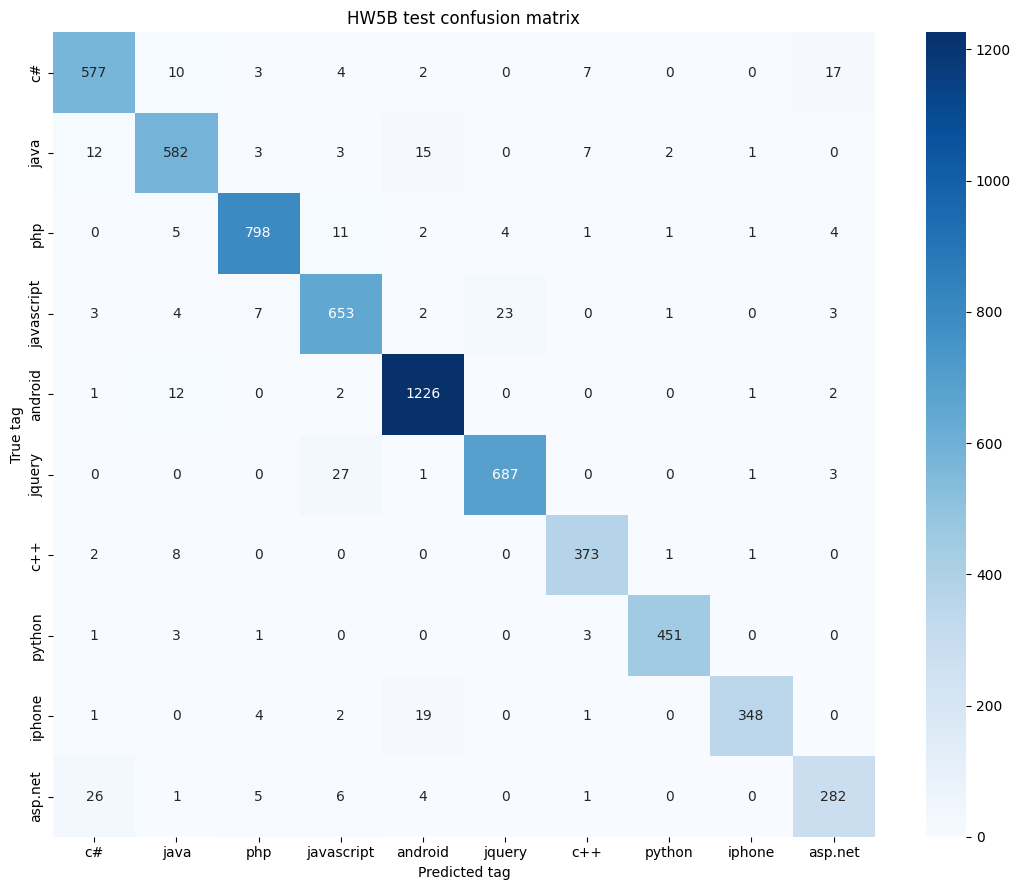

              precision    recall  f1-score   support

          c#     0.9262    0.9306    0.9284       620
        java     0.9312    0.9312    0.9312       625
         php     0.9720    0.9649    0.9684       827
  javascript     0.9223    0.9382    0.9302       696
     android     0.9646    0.9855    0.9750      1244
      jquery     0.9622    0.9555    0.9588       719
         c++     0.9491    0.9688    0.9589       385
      python     0.9890    0.9826    0.9858       459
      iphone     0.9858    0.9280    0.9560       375
     asp.net     0.9068    0.8677    0.8868       325

    accuracy                         0.9525      6275
   macro avg     0.9509    0.9453    0.9480      6275
weighted avg     0.9526    0.9525    0.9524      6275



,precision,recall,f1-score,support
c#,0.926164,0.930645,0.928399,620.00000
java,0.931200,0.931200,0.931200,625.00000
php,0.971985,0.964933,0.968447,827.00000
javascript,0.922316,0.938218,0.930199,696.00000
android,0.964595,0.985531,0.974950,1244.00000
jquery,0.962185,0.955494,0.958828,719.00000
c++,0.949109,0.968831,0.958869,385.00000
python,0.989035,0.982571,0.985792,459.00000
iphone,0.985836,0.928000,0.956044,375.00000
asp.net,0.906752,0.867692,0.886792,325.00000


,true_tag,predicted_tag,count
0,jquery,javascript,27
1,asp.net,c#,26
2,javascript,jquery,23
3,iphone,android,19
4,c#,asp.net,17


In [13]:
# Each fine-tuned split is generated exactly once. All later tables/plots reuse these predictions.
validation_predictions, validation_seconds = generate_rows(
    val_df, val_inputs, constrained_params, lora_request, "validation_constrained", True)
test_predictions, test_seconds = generate_rows(
    test_df, test_inputs, constrained_params, lora_request, "test_constrained", True)
validation_metrics = score(validation_predictions)
test_metrics = score(test_predictions)
display(pd.DataFrame([{"split": "validation", "questions": len(val_df), **validation_metrics},
                      {"split": "test", "questions": len(test_df), **test_metrics}]))
run.log({"validation/accuracy": validation_metrics["accuracy"],
         "validation/macro_f1": validation_metrics["macro_f1"],
         "test/accuracy": test_metrics["accuracy"], "test/macro_f1": test_metrics["macro_f1"]})
log_predictions("validation/predictions", validation_predictions)
log_predictions("test/predictions", test_predictions)
validation_cm = plot_confusion(validation_predictions, "validation")
test_cm = plot_confusion(test_predictions, "test")
print(classification_report(test_predictions["true_tag"], test_predictions["prediction"],
                            labels=class_names, target_names=class_names, digits=4, zero_division=0))
report = classification_report(test_predictions["true_tag"], test_predictions["prediction"],
                               labels=class_names, target_names=class_names, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
display(report_df)
report_df.to_csv(RESULTS_DIR / f"hw5{PART}_test_classification_report.csv")
run.log({"test/classification_report": wandb.Table(dataframe=report_df.reset_index(names="tag"))})
top_confusions = ranked_confusions(test_cm)
display(pd.DataFrame(top_confusions))

## Experiment 1: constrained validation without the adapter

In [14]:
# The same base/instruction checkpoint without the learned LoRA adapter.
# The prompt, tokenizer, tag constraint, and decoding settings are unchanged.
untrained_validation_predictions, untrained_validation_seconds = generate_rows(
    val_df, val_inputs, constrained_params, None, "untrained_validation_constrained", True)
untrained_validation_metrics = score(untrained_validation_predictions)
display(pd.DataFrame([
    {"model": "untrained", **untrained_validation_metrics},
    {"model": "fine-tuned", **validation_metrics},
]))
run.log({"untrained_validation/accuracy": untrained_validation_metrics["accuracy"],
         "untrained_validation/macro_f1": untrained_validation_metrics["macro_f1"],
         "validation/macro_f1_gain": validation_metrics["macro_f1"] - untrained_validation_metrics["macro_f1"]})
log_predictions("untrained_validation/predictions", untrained_validation_predictions)

Adding requests:   0%|          | 0/6276 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/6276 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

untrained_validation_constrained: 6,276 questions in 71.4 seconds; saved hw5B_untrained_validation_constrained.csv


,model,accuracy,macro_f1
0,untrained,0.226418,0.160872
1,fine-tuned,0.955226,0.949372


## Experiment 2: free answers on the same 1,000 monitoring questions

Both models receive the same prompts, greedy decoding, and a 64-token limit.
**Raw exact-match invalid counts** require the entire answer to equal a tag name,
with no normalization; even Part A's deliberately trained leading space fails
this literal check. **Normalized invalid counts** separately remove only outer
whitespace before checking tag membership. Neither check extracts a tag from an
explanation. Raw answers and both counts are saved; length-limited responses
are also reported separately.

In [15]:
untrained_free, untrained_free_seconds = generate_rows(
    monitor_df, monitor_inputs, free_params, None, "untrained_monitor_free", False)
finetuned_free, finetuned_free_seconds = generate_rows(
    monitor_df, monitor_inputs, free_params, lora_request, "finetuned_monitor_free", False)
untrained_invalid_count = int((~untrained_free["valid_tag"]).sum())
finetuned_invalid_count = int((~finetuned_free["valid_tag"]).sum())
untrained_raw_exact_invalid_count = int((~untrained_free["raw_exact_tag"]).sum())
finetuned_raw_exact_invalid_count = int((~finetuned_free["raw_exact_tag"]).sum())
free_counts = pd.DataFrame([
    {"model": name, "questions": len(frame), "normalized_invalid_answers": int((~frame["valid_tag"]).sum()),
     "normalized_invalid_percent": 100 * (~frame["valid_tag"]).mean(),
     "raw_exact_tag_failures": int((~frame["raw_exact_tag"]).sum()),
     "length_limited_answers": int(frame["truncated"].sum())}
    for name, frame in [("untrained", untrained_free), ("fine-tuned", finetuned_free)]
])
display(free_counts)
for name, frame in [("untrained", untrained_free), ("fine-tuned", finetuned_free)]:
    print(f"Examples of raw exact-match failures for {name} (no whitespace normalization):")
    display(frame.loc[~frame["raw_exact_tag"], ["id", "true_tag", "raw_response", "valid_tag", "finish_reason"]].head(10))
    log_predictions(f"free_answers/{name}", frame)
    run.log({f"free_answers/{name}_invalid_count": int((~frame["valid_tag"]).sum()),
             f"free_answers/{name}_normalized_invalid_count": int((~frame["valid_tag"]).sum()),
             f"free_answers/{name}_raw_exact_invalid_count": int((~frame["raw_exact_tag"]).sum()),
             f"free_answers/{name}_truncated_count": int(frame["truncated"].sum())})
run.log({"free_answers/counts": wandb.Table(dataframe=free_counts)})

Adding requests:   0%|          | 0/1000 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1000 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

untrained_monitor_free: 1,000 questions in 31.3 seconds; saved hw5B_untrained_monitor_free.csv


Adding requests:   0%|          | 0/1000 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1000 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

finetuned_monitor_free: 1,000 questions in 17.0 seconds; saved hw5B_finetuned_monitor_free.csv


,model,questions,normalized_invalid_answers,normalized_invalid_percent,raw_exact_tag_failures,length_limited_answers
0,untrained,1000,994,99.4,994,411
1,fine-tuned,1000,0,0.0,0,0


Examples of raw exact-match failures for untrained (no whitespace normalization):


,id,true_tag,raw_response,valid_tag,finish_reason
0,15478,javascript,The text is discussing **JavaScript** and invo...,False,stop
1,49159,asp.net,"The text mentions ""ASP.NET OracleMembershipPro...",False,stop
2,49460,c#,The TEXT is asking about deep copying a `hasht...,False,length
3,50530,python,The text is discussing **Python** code for rep...,False,length
4,54856,jquery,The text is discussing a JavaScript issue rela...,False,stop
5,57062,jquery,The text mentions **jQuery** and refers to a n...,False,stop
6,59692,jquery,The TEXT is discussing jQuery and a loop itera...,False,stop
7,59984,c#,The correct label for this text is: **javascri...,False,length
8,60965,android,The TEXT is asking about parsing XML in **Andr...,False,stop
9,63068,java,"The TEXT is about **Java** code, specifically ...",False,stop


Examples of raw exact-match failures for fine-tuned (no whitespace normalization):


,id,true_tag,raw_response,valid_tag,finish_reason


## Save the measured results

In [16]:
evaluation_summary = {
    "part": PART, "base_model": BASE_MODEL, "base_model_revision": BASE_REVISION,
    "adapter_repo_id": HF_REPO_ID, "adapter_revision": ADAPTER_REVISION,
    "dataset_sha256": DATASET_SHA256, "class_names": class_names,
    "validation_questions": len(val_df), "test_questions": len(test_df), "monitoring_questions": len(monitor_df),
    "validation_accuracy": validation_metrics["accuracy"], "validation_macro_f1": validation_metrics["macro_f1"],
    "test_accuracy": test_metrics["accuracy"], "test_macro_f1": test_metrics["macro_f1"],
    "untrained_validation_accuracy": untrained_validation_metrics["accuracy"],
    "untrained_validation_macro_f1": untrained_validation_metrics["macro_f1"],
    "untrained_invalid_count": untrained_invalid_count,
    "finetuned_invalid_count": finetuned_invalid_count,
    "untrained_normalized_invalid_count": untrained_invalid_count,
    "finetuned_normalized_invalid_count": finetuned_invalid_count,
    "untrained_raw_exact_invalid_count": untrained_raw_exact_invalid_count,
    "finetuned_raw_exact_invalid_count": finetuned_raw_exact_invalid_count,
    "untrained_truncated_count": int(untrained_free["truncated"].sum()),
    "finetuned_truncated_count": int(finetuned_free["truncated"].sum()),
    "invalid_answer_definition": "raw_response.strip() not in class_names; no other normalization",
    "normalized_invalid_answer_definition": "raw_response.strip() not in class_names; only outer whitespace is removed",
    "raw_exact_invalid_answer_definition": "raw_response not in class_names; no normalization, including whitespace",
    "legacy_invalid_count_note": "untrained_invalid_count and finetuned_invalid_count alias the normalized counts",
    "free_max_tokens": FREE_MAX_TOKENS, "constrained_max_tokens": CONSTRAINED_MAX_TOKENS,
    "top_confusions": top_confusions, "tokenization_example": tokenization_example,
    "gpu_name": GPU_NAME, "wandb_run_url": run.url,
    "inference_seconds": {"validation": validation_seconds, "test": test_seconds,
                          "untrained_validation": untrained_validation_seconds,
                          "untrained_free": untrained_free_seconds, "finetuned_free": finetuned_free_seconds},
}
summary_path = RESULTS_DIR / f"evaluation_summary_{PART}.json"
summary_path.write_text(json.dumps(evaluation_summary, indent=2))
run.summary.update({k: v for k, v in evaluation_summary.items()
                    if isinstance(v, (int, float, str, bool))})
print("Saved actual evaluation results to", summary_path)

Saved actual evaluation results to /content/drive/MyDrive/HW5_Decoder_Tags/results/evaluation_summary_B.json


In [17]:
HW4_ROWS = [{'model': 'HW4A ModernBERT classification head', 'training_questions': 29287, 'trainable_parameters': 149612554, 'training_time_seconds': 491.99999999999994, 'peak_gpu_memory_gb': 7.05, 'validation_macro_f1': 0.9326416716, 'test_macro_f1': 0.9222282219}, {'model': 'HW4B Qwen3 base classification head', 'training_questions': 5000, 'trainable_parameters': 139481088, 'training_time_seconds': 1056.0, 'peak_gpu_memory_gb': 4.66, 'validation_macro_f1': 0.9456519408, 'test_macro_f1': 0.9412107298, 'test_accuracy': 0.9464541833}]

## Compare the classification heads (part 1), Part A, and Part B

In [21]:
# Part A inference must run before Part B inference so that these are measured results.
required_files = ["evaluation_summary_A.json", "masking_A.json"]
missing = [name for name in required_files if not (RESULTS_DIR / name).exists()]
assert not missing, f"Run Part A training and inference first. Missing: {missing}"
evaluation_a = json.loads((RESULTS_DIR / "evaluation_summary_A.json").read_text())
assert evaluation_a["part"] == "A"
assert evaluation_a["base_model"] == "Qwen/Qwen3-1.7B-Base"
assert evaluation_a["dataset_sha256"] == DATASET_SHA256
assert evaluation_a["class_names"] == class_names
a_repo_id = evaluation_a["adapter_repo_id"]
a_revision = evaluation_a["adapter_revision"]
assert isinstance(a_repo_id, str) and a_repo_id.count("/") == 1
assert isinstance(a_revision, str) and len(a_revision) == 40 and all(c in "0123456789abcdef" for c in a_revision)
training_a_path = RESULTS_DIR / "training_summary_A.json"
recover_training_a = not training_a_path.exists()
if recover_training_a:
    # Recover the actual metadata from the same immutable adapter evaluated in A.
    # Its upload commit cannot be embedded before that upload; record it below.
    recovered_path = hf_hub_download(a_repo_id, "training_summary_A.json", revision=a_revision)
    training_a = json.loads(Path(recovered_path).read_text())
    training_a.setdefault("adapter_revision", a_revision)
else:
    training_a = json.loads(training_a_path.read_text())

assert training_a["part"] == "A"
assert training_a["base_model"] == evaluation_a["base_model"]
assert training_a["adapter_repo_id"] == a_repo_id
assert training_a["training_questions"] == 5000
assert training_a["prompt_format"] == "hw5_single_tag_v1"
a_base_revision = training_a.get("base_model_revision", training_a.get("model_revision"))
assert isinstance(a_base_revision, str) and len(a_base_revision) == 40
assert a_base_revision == evaluation_a["base_model_revision"], "Part A base-model commits do not match."
masking_a = json.loads((RESULTS_DIR / "masking_A.json").read_text())
for previous in [training_a, evaluation_a]:
    assert previous["dataset_sha256"] == DATASET_SHA256
    assert previous["class_names"] == class_names
assert training_a["adapter_revision"] == evaluation_a["adapter_revision"], "Part A results do not match its recorded adapter."
if recover_training_a:
    training_a_path.write_text(json.dumps(training_a, indent=2), encoding="utf-8")
    print("Restored verified Part A training summary from", a_repo_id, "at", a_revision)

comparison_rows = [dict(row) for row in HW4_ROWS]
for name, train, evaluation in [
    ("HW5A Qwen3 base language head (TRL)", training_a, evaluation_a),
    ("HW5B Qwen3 instruction language head (Axolotl)", training_summary, evaluation_summary),
]:
    comparison_rows.append({"model": name, "training_questions": train["training_questions"],
        "trainable_parameters": train["trainable_parameters"],
        "training_time_seconds": train["training_time_seconds"],
        "peak_gpu_memory_gb": train["peak_gpu_memory_gb"],
        "validation_macro_f1": evaluation["validation_macro_f1"], "test_macro_f1": evaluation["test_macro_f1"]})
comparison = pd.DataFrame(comparison_rows)
comparison["training_time_minutes"] = comparison["training_time_seconds"] / 60
comparison = comparison[["model", "training_questions", "trainable_parameters", "training_time_minutes",
                         "peak_gpu_memory_gb", "validation_macro_f1", "test_macro_f1"]]
display(comparison)
comparison.to_csv(RESULTS_DIR / "hw4_hw5_comparison.csv", index=False)
comparison_markdown = comparison.to_markdown(index=False, floatfmt=".4f")
(RESULTS_DIR / "comparison_table.md").write_text(comparison_markdown)
run.log({"comparison/hw4_hw5": wandb.Table(dataframe=comparison)})
print("Training hardware:", {"HW4": "A100 40GB", "HW5A": training_a["gpu_name"],
                            "HW5B": training_summary["gpu_name"]})
print("HW4 time/memory values were preserved at their reported precision; differences in hardware and memory measurement affect comparisons.")

delta_f1 = evaluation_summary["test_macro_f1"] - evaluation_a["test_macro_f1"]
if abs(delta_f1) >= 0.005:
    preferred = "Part B" if delta_f1 > 0 else "Part A"
    reason = "it has the higher measured test macro-F1 in this run"
else:
    preferred = "Part B" if training_summary["training_time_seconds"] < training_a["training_time_seconds"] else "Part A"
    reason = "the test macro-F1 scores are within 0.5 percentage points and it used less measured training time"
hardware_note = "the same reported GPU" if training_a["gpu_name"] == training_summary["gpu_name"] else "different GPUs, so speed is not an isolated framework comparison"
analysis_text = (
    f"Part B achieved test macro-F1 {test_metrics['macro_f1']:.4f} and accuracy {test_metrics['accuracy']:.4f}, "
    f"compared with Part A's {evaluation_a['test_macro_f1']:.4f} and {evaluation_a['test_accuracy']:.4f}; "
    f"the macro-F1 difference was {100 * delta_f1:+.2f} percentage points. "
    f"Part B trained in {training_summary['training_time_seconds']/60:.2f} minutes with "
    f"{training_summary['peak_gpu_memory_gb']:.2f} GB peak GPU memory, compared with "
    f"{training_a['training_time_seconds']/60:.2f} minutes and {training_a['peak_gpu_memory_gb']:.2f} GB for Part A "
    f"({hardware_note}). "
    f"Before fine-tuning, the instruction model's constrained validation macro-F1 was "
    f"{untrained_validation_metrics['macro_f1']:.4f}, versus {evaluation_a['untrained_validation_macro_f1']:.4f} for the base model. "
    f"For unconstrained answers, raw exact-match invalid counts were {untrained_raw_exact_invalid_count}/1,000 for the untrained instruction model "
    f"and {evaluation_a['untrained_raw_exact_invalid_count']}/1,000 for the untrained base model; "
    f"removing only outer whitespace yielded normalized invalid counts of {untrained_invalid_count}/1,000 and "
    f"{evaluation_a['untrained_normalized_invalid_count']}/1,000, respectively. "
    f"After fine-tuning, the respective raw exact-match invalid counts were {finetuned_raw_exact_invalid_count}/1,000 and "
    f"{evaluation_a['finetuned_raw_exact_invalid_count']}/1,000, while the normalized counts were {finetuned_invalid_count}/1,000 and "
    f"{evaluation_a['finetuned_normalized_invalid_count']}/1,000; both models used a 64-token limit and the raw check counts "
    "Part A's trained leading space as extra text. "
    f"For this task I would choose {preferred} because {reason}, while treating this single-seed comparison as descriptive rather than conclusive."
)
display(Markdown(analysis_text))
(RESULTS_DIR / "analysis_B.md").write_text(analysis_text)

Restored verified Part A training summary from rajatsxngh/hw5a-qwen3-base-tag-adapter at e6830856e4882d402b245a972d3df87aac01f702


,model,training_questions,trainable_parameters,training_time_minutes,peak_gpu_memory_gb,validation_macro_f1,test_macro_f1
0,HW4A ModernBERT classification head,29287,149612554,8.200000,7.050000,0.932642,0.922228
1,HW4B Qwen3 base classification head,5000,139481088,17.600000,4.660000,0.945652,0.941211
2,HW5A Qwen3 base language head (TRL),5000,139460608,40.646595,11.140435,0.948848,0.949779
3,HW5B Qwen3 instruction language head (Axolotl),5000,139460608,39.517461,2.316281,0.949372,0.947952


Training hardware: {'HW4': 'A100 40GB', 'HW5A': 'NVIDIA L4', 'HW5B': 'NVIDIA L4'}
HW4 time/memory values were preserved at their reported precision; differences in hardware and memory measurement affect comparisons.


Part B achieved test macro-F1 0.9480 and accuracy 0.9525, compared with Part A's 0.9498 and 0.9539; the macro-F1 difference was -0.18 percentage points. Part B trained in 39.52 minutes with 2.32 GB peak GPU memory, compared with 40.65 minutes and 11.14 GB for Part A (the same reported GPU). Before fine-tuning, the instruction model's constrained validation macro-F1 was 0.1609, versus 0.7454 for the base model. For unconstrained answers, raw exact-match invalid counts were 994/1,000 for the untrained instruction model and 1000/1,000 for the untrained base model; removing only outer whitespace yielded normalized invalid counts of 994/1,000 and 166/1,000, respectively. After fine-tuning, the respective raw exact-match invalid counts were 0/1,000 and 1000/1,000, while the normalized counts were 0/1,000 and 0/1,000; both models used a 64-token limit and the raw check counts Part A's trained leading space as extra text. For this task I would choose Part B because the test macro-F1 scores are within 0.5 percentage points and it used less measured training time, while treating this single-seed comparison as descriptive rather than conclusive.

1152

## Generate answers supported by tokenizer and masking outputs

In [22]:
spacing = evaluation_a["tokenization_example"]
assert spacing is not None, "Part A must save its tokenizer demonstration."
spaced, bare = spacing[" javascript"], spacing["javascript"]

def supervised_text(evidence):
    if "supervised_text" in evidence:
        return evidence["supervised_text"]
    raise KeyError("Masking evidence must contain the actual supervised_text from the training notebook.")

answer_1 = (
    f"For the Part A tokenizer, ` javascript` has IDs `{spaced['ids']}` and tokens `{spaced['tokens']}`, "
    f"whereas `javascript` has IDs `{bare['ids']}` and tokens `{bare['tokens']}`. "
    "The leading space is part of the completion learned during training, so the constrained choices must preserve it. "
    "The prompt ends immediately after `### LABEL:` and the completion supplies the next space. "
    "Moving that space into the prompt or changing another character can alter the token boundary or the prefix context, "
    "so inference would ask for a token continuation different from the one used for training."
)
answer_2 = (
    f"The saved masking outputs show that Part A supervises `{supervised_text(masking_a)}` and "
    f"Part B supervises `{supervised_text(masking_evidence)}`. "
    "Question/prompt positions have labels of -100 and therefore do not contribute to cross-entropy; "
    "Part B's empty `<think>` block is also excluded, while its answer-ending `<|im_end|>` is supervised. "
    "If the question also carried labels, the causal language-model objective would additionally train the model "
    "to predict each question token from its preceding context. "
    "Because questions are much longer than tags, most supervised positions would then be question tokens, "
    "changing the loss weighting and spending gradient updates on reproducing input text rather than only predicting the tag."
)
answer_3 = (
    "Constrained decoding limits a completed answer to the supplied set of tag strings; it does not guarantee "
    "that the selected tag is semantically correct. "
    f"Without that constraint, raw exact-match invalid counts were {evaluation_a['untrained_raw_exact_invalid_count']} and "
    f"{evaluation_a['finetuned_raw_exact_invalid_count']} for Part A's untrained and fine-tuned models, and "
    f"{untrained_raw_exact_invalid_count} and {finetuned_raw_exact_invalid_count} for Part B, each out of 1,000 monitoring questions. "
    "This literal check requires the raw answer to equal one of the ten tag names without any normalization; "
    "it therefore counts even Part A's deliberately trained leading space as extra text. "
    f"For a separately labeled whitespace-normalized check, the invalid counts were {evaluation_a['untrained_normalized_invalid_count']} and "
    f"{evaluation_a['finetuned_normalized_invalid_count']} for Part A, and {untrained_invalid_count} and "
    f"{finetuned_invalid_count} for Part B in the same model order. "
    "The normalized check removes only outer whitespace and still rejects explanations, punctuation, and altered tag names. "
    f"The corresponding length-limit counts were {evaluation_a['untrained_truncated_count']}, "
    f"{evaluation_a['finetuned_truncated_count']}, {int(untrained_free['truncated'].sum())}, and "
    f"{int(finetuned_free['truncated'].sum())}; these report the limits of the 64-token free-answer experiment. "
    "The constraint is most useful when a model otherwise writes explanations or other invalid formats, "
    "and it also enforces a consistent downstream interface after fine-tuning. "
    "The notebook separately asserts successful completion and exact allowed output for constrained requests."
)
answer_4 = (
    "HW4's classification head computes ten class scores from the model's sequence representation and predicts "
    "the largest score; inference needs the fine-tuned backbone, classification head, tokenizer, and label mapping. "
    "HW5 retains the vocabulary language-model head and generates a tag token by token, so inference needs the "
    "base model plus its LoRA adapter, the matching tokenizer and prompt/chat template, generation settings, "
    "and the allowed tag list for constrained decoding. "
    f"The HW4 Qwen classification head achieved test macro-F1 {HW4_ROWS[1]['test_macro_f1']:.4f}, "
    f"compared with {evaluation_a['test_macro_f1']:.4f} for HW5A and {test_metrics['macro_f1']:.4f} for HW5B. "
    "All three Qwen experiments used the same 5,000 training questions; the comparison table reports the "
    "measured parameter counts, training time, memory, and validation/test macro-F1 rather than assuming that "
    "one prediction method is always faster or more accurate."
)
answers = {"1. Why the leading space matters": answer_1,
           "2. Why supervise only the answer": answer_2,
           "3. What constrained decoding guarantees": answer_3,
           "4. Classification head versus language head": answer_4}
answers_markdown = "\n\n".join(f"### {question}\n\n{answer}" for question, answer in answers.items())
display(Markdown(answers_markdown))
(RESULTS_DIR / "answers_B.md").write_text(answers_markdown)

### 1. Why the leading space matters

For the Part A tokenizer, ` javascript` has IDs `[35710]` and tokens `['Ġjavascript']`, whereas `javascript` has IDs `[14073]` and tokens `['javascript']`. The leading space is part of the completion learned during training, so the constrained choices must preserve it. The prompt ends immediately after `### LABEL:` and the completion supplies the next space. Moving that space into the prompt or changing another character can alter the token boundary or the prefix context, so inference would ask for a token continuation different from the one used for training.

### 2. Why supervise only the answer

The saved masking outputs show that Part A supervises ` asp.net<|endoftext|>` and Part B supervises `asp.net<|im_end|>`. Question/prompt positions have labels of -100 and therefore do not contribute to cross-entropy; Part B's empty `<think>` block is also excluded, while its answer-ending `<|im_end|>` is supervised. If the question also carried labels, the causal language-model objective would additionally train the model to predict each question token from its preceding context. Because questions are much longer than tags, most supervised positions would then be question tokens, changing the loss weighting and spending gradient updates on reproducing input text rather than only predicting the tag.

### 3. What constrained decoding guarantees

Constrained decoding limits a completed answer to the supplied set of tag strings; it does not guarantee that the selected tag is semantically correct. Without that constraint, raw exact-match invalid counts were 1000 and 1000 for Part A's untrained and fine-tuned models, and 994 and 0 for Part B, each out of 1,000 monitoring questions. This literal check requires the raw answer to equal one of the ten tag names without any normalization; it therefore counts even Part A's deliberately trained leading space as extra text. For a separately labeled whitespace-normalized check, the invalid counts were 166 and 0 for Part A, and 994 and 0 for Part B in the same model order. The normalized check removes only outer whitespace and still rejects explanations, punctuation, and altered tag names. The corresponding length-limit counts were 94, 0, 411, and 0; these report the limits of the 64-token free-answer experiment. The constraint is most useful when a model otherwise writes explanations or other invalid formats, and it also enforces a consistent downstream interface after fine-tuning. The notebook separately asserts successful completion and exact allowed output for constrained requests.

### 4. Classification head versus language head

HW4's classification head computes ten class scores from the model's sequence representation and predicts the largest score; inference needs the fine-tuned backbone, classification head, tokenizer, and label mapping. HW5 retains the vocabulary language-model head and generates a tag token by token, so inference needs the base model plus its LoRA adapter, the matching tokenizer and prompt/chat template, generation settings, and the allowed tag list for constrained decoding. The HW4 Qwen classification head achieved test macro-F1 0.9412, compared with 0.9498 for HW5A and 0.9480 for HW5B. All three Qwen experiments used the same 5,000 training questions; the comparison table reports the measured parameter counts, training time, memory, and validation/test macro-F1 rather than assuming that one prediction method is always faster or more accurate.

3502

In [23]:
# Save plots, summaries, and predictions as an artifact; keep all notebook outputs visible.
artifact = wandb.Artifact(f"hw5{PART.lower()}-evaluation", type="evaluation")
for path in sorted(RESULTS_DIR.glob(f"hw5{PART}_*")):
    if path.is_file():
        artifact.add_file(str(path))
for name in [f"evaluation_summary_{PART}.json", f"analysis_{PART}.md"]:
    artifact.add_file(str(RESULTS_DIR / name))
if PART == "B":
    for name in ["hw4_hw5_comparison.csv", "comparison_table.md", "answers_B.md"]:
        artifact.add_file(str(RESULTS_DIR / name))
run.log_artifact(artifact)
print("Completed evaluation run:", run.url)
run.finish()
print("Save this notebook with its outputs. Fill the final markdown cells from the generated analysis files before submission.")

Completed evaluation run: https://wandb.ai/rajat-utd/hw5_decoder_tags/runs/lxt8b01s


free_answers/fine-tuned_invalid_count,▁
free_answers/fine-tuned_normalized_invalid_count,▁
free_answers/fine-tuned_raw_exact_invalid_count,▁
free_answers/fine-tuned_truncated_count,▁
free_answers/untrained_invalid_count,▁
free_answers/untrained_normalized_invalid_count,▁
free_answers/untrained_raw_exact_invalid_count,▁
free_answers/untrained_truncated_count,▁
test/accuracy,▁
test/macro_f1,▁
+5,...


Save this notebook with its outputs. Fill the final markdown cells from the generated analysis files before submission.


## Part B analysis

Part B reached a test macro-F1 of 0.9480 (accuracy 0.9525), almost the same as Part A's 0.9498 (0.9539), a gap of only 0.18 points. Both trained on the same L4 GPU in about the same time (39.5 vs 40.6 minutes) with about the same peak GPU memory (11.05 vs 11.14 GiB). The big difference is before fine-tuning: the untrained base model simply continues the "### LABEL:" pattern and usually writes a tag (166 of 1,000 free answers were not a tag; constrained validation macro-F1 0.745), while the untrained instruction model writes an explanation such as "The text is discussing **JavaScript**…" (994 of 1,000 not a tag, 411 hit the 64-token limit), and forcing it to start with a tag gives a macro-F1 of only 0.161. After fine-tuning, both models answer with just the tag every time (0 of 1,000 invalid), so the instruction model's poor start disappears. I would choose Part A: it scored slightly higher, its untrained model is already a useful starting point, and it needs only a plain prompt with TRL instead of a chat template and an Axolotl setup — though with one run each, the 0.18-point gap is within noise.

## Comparison table

| Model | Training questions | Trainable parameters | Training time (minutes) | GPU memory (reported; see note) | Validation macro-F1 | Test macro-F1 |
| --- | --- | --- | --- | --- | --- | --- |
| ModernBERT-base classification head (part 1) | 29287 | 149612554 | 8.2000 | 7.0500 | 0.9326 | 0.9222 |
| Qwen3-1.7B-Base classification head (part 1) | 5000 | 139481088 | 17.6000 | 4.6600 | 0.9457 | 0.9412 |
| Part A: Qwen3-1.7B-Base language head (TRL) | 5000 | 139460608 | 40.6466 | 11.1404 | 0.9488 | 0.9498 |
| Part B: Qwen3-1.7B instruction language head (Axolotl) | 5000 | 139460608 | 39.5175 | 11.05 | 0.9494 | 0.9480 |

Part 1 used an A100 40GB; Part A and Part B used an NVIDIA L4. Part A/B memory values are in GiB; part 1 time and memory values retain their originally reported units and precision. Differences in hardware and memory measurement affect comparisons.


**Memory reporting correction:** The original 2.316281 GiB value recorded in the training summary is the final interval, because Axolotl resets its peak counters after logging. The largest saved `memory/max_allocated (GiB)` value is 11.05 GiB, rounded to two decimals. Part A reports a run-wide PyTorch peak; the two measurements should therefore be compared with caution.


## Discussion

### 1. Why the leading space matters

The Part A tokenizer turns ` javascript` (with the space) into one token, ID `35710` (`Ġjavascript`, where `Ġ` marks the space), but `javascript` without the space is a different token, ID `14073`. In training, the prompt always ended with `### LABEL:` and the completion started with the space, so the model learned that the token after `LABEL:` is a space-prefixed tag token such as `35710`. The constrained choices at inference start with a space for the same reason: they must match the tokens the model was trained to produce. If they did not (for example, choices without the space), the model would be forced to start with token `14073`, which it never learned to produce after `LABEL:`, so its scores there would be unreliable and accuracy would drop. The same happens if the prompt changes by even one character: a trailing space after `LABEL:` would already use up the space, so the model sees a token sequence it never saw in training and has to continue with the no-space token. That is why the inference notebooks build the prompts with exactly the same function as training.

### 2. Why supervise only the answer

The saved masking outputs show that Part A supervises ` asp.net<|endoftext|>` and Part B supervises `asp.net<|im_end|>`. Question/prompt positions have labels of -100 and therefore do not contribute to cross-entropy; Part B's empty `<think>` block is also excluded, while its answer-ending `<|im_end|>` is supervised. If the question also carried labels, the causal language-model objective would additionally train the model to predict each question token from its preceding context. Because questions are much longer than tags, most supervised positions would then be question tokens, changing the loss weighting and spending gradient updates on reproducing input text rather than only predicting the tag.

### 3. What constrained decoding guarantees

Constrained decoding guarantees that every answer is exactly one of the ten tag names; it does not guarantee that the tag is correct. It matters most when a model does not already answer in the right format. Without the constraint, on the 1,000 monitoring questions the untrained instruction model gave a non-tag answer 994 times (mostly explanations such as "The text is discussing **JavaScript**…", with 411 hitting the 64-token limit), and the untrained base model 166 times (94 hit the limit). After fine-tuning, both models gave 0 non-tag answers out of 1,000. For Part A, these counts ignore the leading space the model was trained to write; counted character by character, every Part A answer starts with that space, so a strict exact-match check would mark all 1,000 answers of both Part A models as invalid, which says nothing about the answers themselves. So for the untrained models the constraint is essential, while for the fine-tuned models it is a safety net that does not change any prediction here.

### 4. Classification head versus language head

The classification head from part 1 computes ten class scores from the model's sequence representation and predicts the largest score; inference needs the fine-tuned backbone, classification head, tokenizer, and label mapping. The language-head approach retains the vocabulary language-model head and generates a tag token by token, so inference needs the base model plus its LoRA adapter, the matching tokenizer and prompt/chat template, generation settings, and the allowed tag list for constrained decoding. The part-1 Qwen classification head achieved test macro-F1 0.9412, compared with 0.9498 for Part A and 0.9480 for Part B. All three Qwen experiments used the same 5,000 training questions; the comparison table reports the measured parameter counts, training time, memory, and validation/test macro-F1 rather than assuming that one prediction method is always faster or more accurate.


## Sources and reproducibility

API references: [vLLM 0.11 structured outputs](https://docs.vllm.ai/en/v0.11.0/features/structured_outputs.html),
[vLLM 0.11 LoRA adapters](https://docs.vllm.ai/en/v0.11.0/features/lora.html),
and [Hugging Face snapshot downloads](https://huggingface.co/docs/huggingface_hub/guides/download).
Training selects the checkpoint using only monitoring loss. Validation and test predictions
are generated once per fine-tuned model and reused for every reported metric and plot.